[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/langchain-ai/langchain-academy/blob/main/module-2/multiple-schemas.ipynb) [![Open in LangChain Academy](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66e9eba12c7b7688aa3dbb5e_LCA-badge-green.svg)](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58239434-lesson-3-multiple-schemas)

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎯 Multiple Schemas

**一句话定位**：通常一个图只用一套 schema，但有时需要更细的控制——内部节点间传的数据不想暴露在图的输入/输出里，或者图的输入/输出 schema 想各自收紧。本节讲这两类场景。

- 内部节点之间可能要传一些**图的输入/输出并不需要**的信息
- 可能想让图用**不同的** input / output schema——比如输出只想暴露一个关键字段

下面分别用 `PrivateState` 和显式的 `input`/`output` schema 来实现。

</div>

## Private State

先看在节点间传递[私有 state（private state）](https://docs.langchain.com/oss/python/langgraph/use-graph-api#pass-private-state-between-nodes)的用法——适合图内部中间计算逻辑需要、但跟整体输入/输出无关的数据。

定义 `OverallState` 和 `PrivateState` 两个 schema：`node_2` 用 `PrivateState` 作为输入，但写出到 `OverallState`。

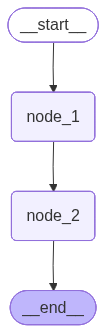

In [2]:
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

class OverallState(TypedDict):
    foo: int

class PrivateState(TypedDict):
    baz: int

def node_1(state: OverallState) -> PrivateState:
    print("---Node 1---")
    return {"baz": state['foo'] + 1}

def node_2(state: PrivateState) -> OverallState:
    print("---Node 2---")
    return {"foo": state['baz'] + 1}

# Build graph
builder = StateGraph(OverallState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)

# Logic
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [3]:
graph.invoke({"foo" : 1})

---Node 1---
---Node 2---


{'foo': 3}

`baz` 这个字段只存在于 `PrivateState` 里。`node_2` 以 `PrivateState` 作为输入，但写出到 `OverallState`——所以 `baz` 不在 `OverallState` 里，图的最终输出中自然就看不到它。

## Input / Output Schema

默认情况下，`StateGraph` 只接受单一 schema，所有节点都按这套 schema 通信。但其实也可以[为图显式定义 input 和 output schema](https://docs.langchain.com/oss/python/langgraph/use-graph-api#define-input-and-output-schemas)。

常见做法是定义一个包含**所有**图运行相关 key 的“内部”schema，再用专门的 `input`/`output` schema 去约束对外暴露的输入输出范围。

先用单一 schema 跑一遍作对比。

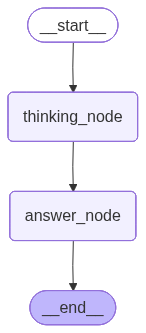

In [4]:
class OverallState(TypedDict):
    question: str
    answer: str
    notes: str


def thinking_node(state: OverallState):
    return {"answer": "bye", "notes": "... his name is Lance"}


def answer_node(state: OverallState):
    return {"answer": "bye Lance"}


graph = StateGraph(OverallState)
graph.add_node("answer_node", answer_node)
graph.add_node("thinking_node", thinking_node)
graph.add_edge(START, "thinking_node")
graph.add_edge("thinking_node", "answer_node")
graph.add_edge("answer_node", END)

graph = graph.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

可以看到 `invoke` 的输出包含了 `OverallState` 里的所有 key。

In [5]:
graph.invoke({"question":"hi"})

{'question': 'hi', 'answer': 'bye Lance', 'notes': '... his name is Lance'}

现在换成专门的 `input` / `output` schema。

`input` / `output` schema 本质是对图输入输出允许暴露的 key 做**过滤**。另外，给节点标注 `state: InputState` 这样的类型提示，可以指定该节点期望的输入 schema——在图里混用多套 schema 时这一点很重要。

下面的例子里，`answer_node` 的输出类型提示会被过滤为 `OutputState`。

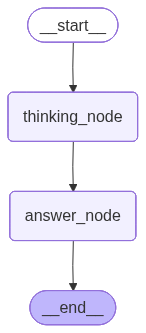

{'answer': 'bye Lance'}

In [6]:
class InputState(TypedDict):
    question: str

class OutputState(TypedDict):
    answer: str

class OverallState(TypedDict):
    question: str
    answer: str
    notes: str

def thinking_node(state: InputState):
    return {"answer": "bye", "notes": "... his is name is Lance"}

def answer_node(state: OverallState) -> OutputState:
    return {"answer": "bye Lance"}

graph = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)
graph.add_node("answer_node", answer_node)
graph.add_node("thinking_node", thinking_node)
graph.add_edge(START, "thinking_node")
graph.add_edge("thinking_node", "answer_node")
graph.add_edge("answer_node", END)

graph = graph.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

graph.invoke({"question":"hi"})

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🗺️ 全景图：每个 schema 出现在哪、怎么用

**读图方法**：绿 = 主 schema（公开） · 红 = 私有 schema · 青 = InputState · 黄 = OutputState · 灰 = 节点。箭头上的数字是执行顺序。

</div>

### 图 1：PrivateState 版本（`node_1` ⇄ `node_2`）

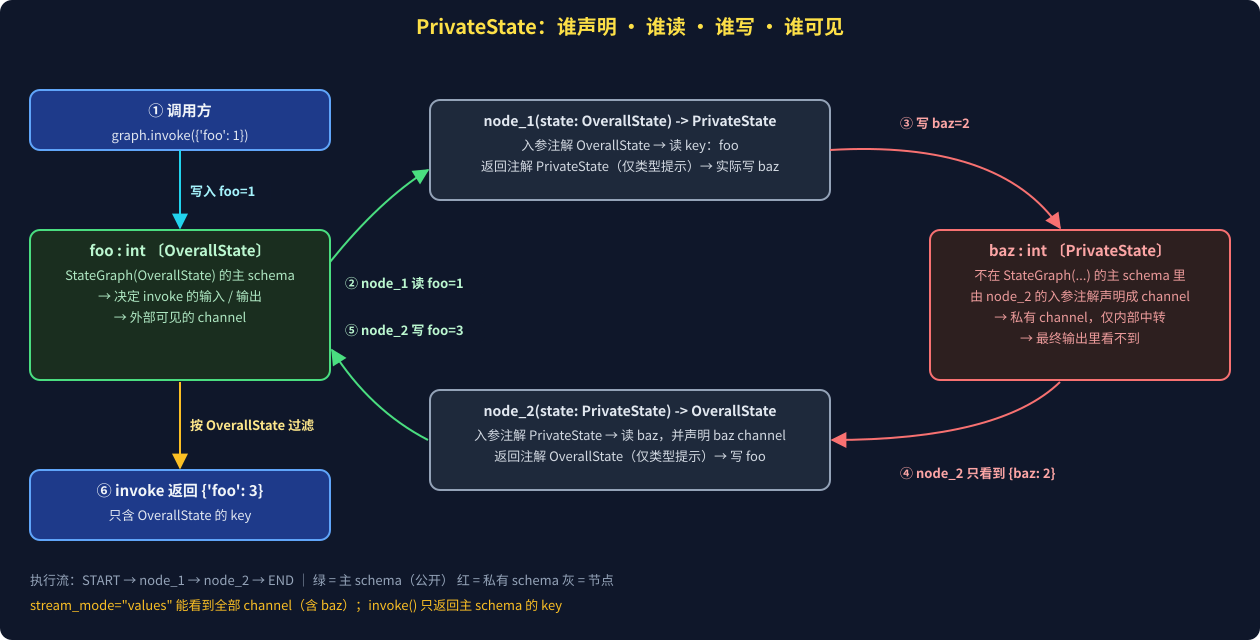

In [ ]:
from IPython.display import SVG
SVG(filename="assets/003_private_state.svg")   # 与本 notebook 同目录的 assets/

**图 1 要点**

| schema | 出现的地方 | 作用 |
|---|---|---|
| `OverallState` | `StateGraph(OverallState)` · `node_1` 入参注解 · `node_2` 返回注解（仅提示） | 主 schema：定义 `foo` channel，决定 `invoke` 的输入/输出 |
| `PrivateState` | `node_2` **入参**注解（真正起作用） · `node_1` 返回注解（仅提示） | 由 `node_2` 的入参注解声明出私有 channel `baz`，**不出现在 invoke 结果里** |

- **入参注解 = 该节点能读到哪些 key**（`node_2` 只看到 `{baz: 2}`，看不到 `foo`）
- **返回注解只是类型提示**：实测把 `node_1` 的返回注解改成 `OverallState`，结果照样 `{'foo': 3}`——`baz` 能被写入，靠的是 `node_2` 的入参注解声明了它

### 图 2：Input / Output / Overall 三套 schema

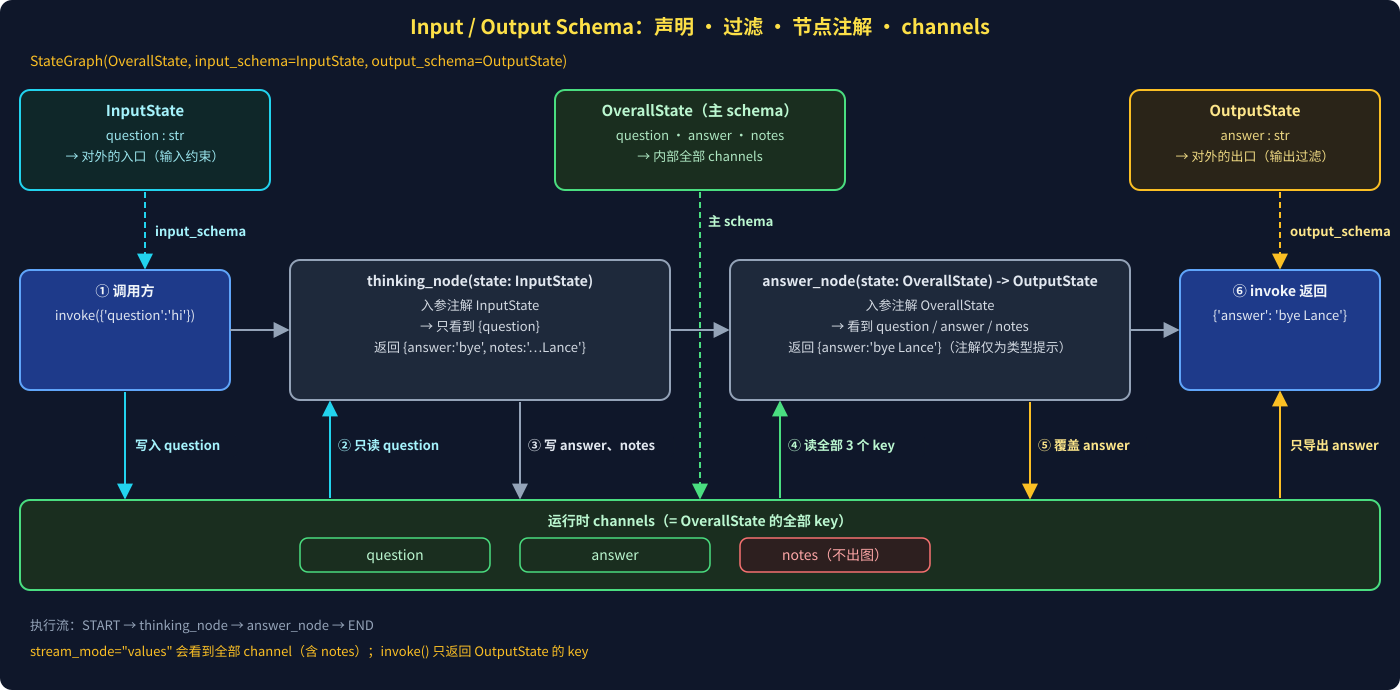

In [ ]:
from IPython.display import SVG
SVG(filename="assets/003_input_output_schema.svg")   # 与本 notebook 同目录的 assets/

**图 2 要点**

| schema | 出现的地方 | 作用 |
|---|---|---|
| `OverallState` | `StateGraph(OverallState, …)` · `answer_node` 入参注解 | 主 schema：所有 channels = `question` / `answer` / `notes` |
| `InputState` | `input_schema=` · `thinking_node` 入参注解 | 约束对外输入；`thinking_node` **只看到 `{question}`** |
| `OutputState` | `output_schema=`（真正起过滤作用） · `answer_node` 返回注解（仅提示） | `invoke` 结果过滤为只剩 `answer`；`notes` 留在内部 |

本机 langgraph 1.2 实测：`thinking_node` 看到 `{'question':'hi'}`，`answer_node` 看到三个 key，`invoke` 返回 `{'answer':'bye Lance'}`。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**关键洞察**：`output_schema` / 私有 schema 只过滤 **`invoke` 的返回值**，不是真正的"隐藏"：channel 仍在 state 里，`stream_mode="values"` 和 checkpoint 里都看得到（`baz`、`notes` 都会出现）。

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`StateGraph(Overall, input_schema=In, output_schema=Out)` 管对外边界；节点**入参注解**决定它能读什么、并顺带声明私有 channel；返回注解只是类型提示。

</div>